IORSIM_BASECASE_INPUT_TRACER_CONCENTRATION.GSG
0 ('p',) ('TRACER_CONCENTRATION["CL"]',) TRCL (210, 266, 23)
--------------------------------------------------


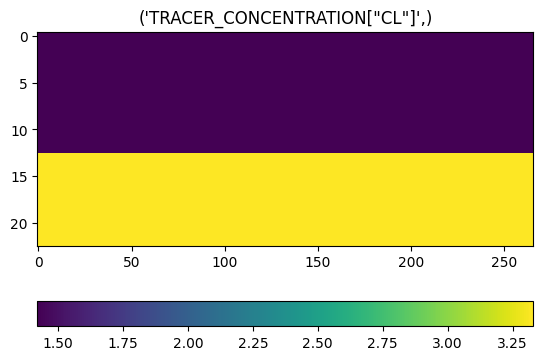

In [ ]:
# Tracer concentration for Ekofisk and Tor
from pathlib import Path
import numpy as np
from IORlib.ECL import INIT_file
from IORlib.GSG import PROP_data, read_prop_file, write_prop_file
from matplotlib import pyplot as pl

home = Path.home()
input = Path('/home/shared/owner/CoP_files/input')
#root = input/'Tracers/Tracers'
root = input/'IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

dim = INIT_file(root).dim()
cl = np.zeros(dim, dtype=np.float32)
cl[:, :, :13] = 1.42 # Ekofisk
cl[:, :, 13:] = 3.33 # Tor
ccl = PROP_data('p', 'TRACER_CONCENTRATION["CL"]', 'TRCL', cl, 0)
write_prop_file(Path(f'{root}_TRACER_CONCENTRATION.GSG'), ccl)

file = Path(f'{root}_TRACER_CONCENTRATION.GSG')

print(file.name)
for data in read_prop_file(file, dim=dim):
    print(data.kind, data.type, data.name, data.alias, data.array.shape)
    #print(data.array[:5], data.array[-5:])
    pl.figure()
    pl.title(data.name)
    pl.imshow(data.array[100, :, :].T, origin='upper', aspect=5, interpolation='none')
    pl.colorbar(orientation='horizontal')
print(50*'-')



Model_From_IXF_TRACER_CONCENTRATION.GSG
0 ('p',) ('TRACER_CONCENTRATION["CL"]',) TRCL (25, 25, 5)
--------------------------------------------------


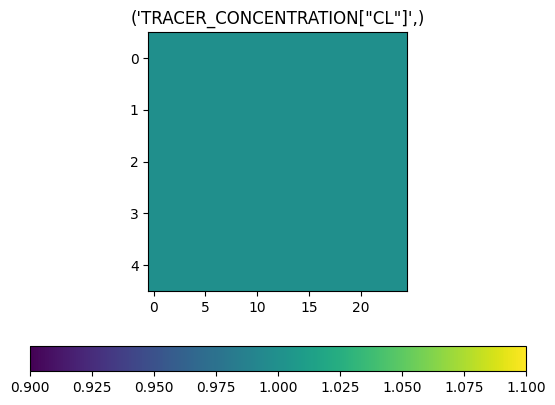

In [2]:
# Tracer concentration for Model_From_IXF
from pathlib import Path
import numpy as np
from IORlib.ECL import INIT_file
from IORlib.GSG import PROP_data, read_prop_file, write_prop_file
from matplotlib import pyplot as pl

input = Path('/home/shared/owner/CoP_files/input')
root = input/'Model_From_IXF/Model_From_IXF'

dim = INIT_file(root).dim()
cl = np.ones(dim, dtype=np.float32)
ccl = PROP_data('p', 'TRACER_CONCENTRATION["CL"]', 'TRCL', cl, 0)
write_prop_file(Path(f'{root}_TRACER_CONCENTRATION.GSG'), ccl)

file = Path(f'{root}_TRACER_CONCENTRATION.GSG')

print(file.name)
for data in read_prop_file(file, dim=dim):
    print(data.kind, data.type, data.name, data.alias, data.array.shape)
    #print(data.array[:5], data.array[-5:])
    pl.figure()
    pl.title(data.name)
    pl.imshow(data.array[1, :, :].T, origin='upper', aspect=5, interpolation='none')
    pl.colorbar(orientation='horizontal')
print(50*'-')


In [ ]:
from math import prod
from pathlib import Path
import numpy as np
from IORlib.ECL import INIT_file
from IORlib.GSG import PROP_data, read_prop_file, File, write_prop_file
from matplotlib import pyplot as pl

home = Path.home()
input = Path('/home/shared/owner/CoP_files/input')
#root = input/'Tracers/Tracers'
root = input/'IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

files = [
    Path(f'{root}_CONNATE_WATER_SATURATION.GSG'),
    Path(f'{root}_FLUID_IN_PLACE_REGION.GSG'),
    Path(f'{root}_CRITICAL_WATER_SATURATION.GSG'),
    Path(f'{root}_POROSITY.GSG'),
    Path(f'{root}_MAX_WATER_SATURATION.GSG'),
    Path(f'{root}_TRACER_CONCENTRATION.GSG'),
    Path(f'{root}_REGIONS.GSG'),
    Path(f'{root}_PERM_I.GSG'),
    Path(f'{root}_RESIDUAL_OIL_SATURATION_TO_WATER_IMBIBITION.GSG'),
    Path(f'{root}_RESIDUAL_OIL_SATURATION_TO_WATER.GSG')
]

#files = list(root.parent.glob('*.GSG'))

dim = INIT_file(root).dim()
#dim = (3,3,3)
eko = np.zeros(dim, dtype=np.float32)
eko[:, :, :14] = 1
tor = np.zeros(dim, dtype=np.float32)
tor[:, :, 14:] = 1
ceko = PROP_data('p', 'TRACER_CONCENTRATION["EKO"]', 'TREKO', eko, 0)
ctor = PROP_data('p', 'TRACER_CONCENTRATION["TOR"]', 'TRTOR', tor, 0)
write_prop_file(Path(f'{root}_TRACER_CONCENTRATION.GSG'), ceko, ctor)

for file in files[5:6]:
    print(file.name)
    for data in read_prop_file(file, dim=dim):
        print(data.kind, data.type, data.name, data.alias, data.array.shape)
        #print(data.array[:5], data.array[-5:])
        pl.figure()
        pl.title(data.name)
        pl.imshow(data.array[100, :, :].T, origin='upper', aspect=5, interpolation='none')
        pl.colorbar(orientation='horizontal')
    print(50*'-')

